# T11. Solapes por patinete y recolocaciones del operador

**Objetivo.** Saber si el piloto ya movía patinetes sin que hubiera un viaje (recolocaciones, recogidas para recargar o mantenimiento), cuántas veces, cuándo y dónde.

**Valor para el proyecto.** Con estaciones, los patinetes se recargan anclados y el operador solo tendría que rebalancear. Si el piloto ya dependía de mover patinetes, la simulación de flota tiene que incluir un escenario de rebalanceo y el tamaño de flota no se puede leer directamente de los 2 331 patinetes observados.

Se encadenan **todos** los viajes de cada patinete (también los no elegibles, porque el patinete se movió o se desbloqueó igualmente) y se mide el salto entre el final de un viaje y el inicio del siguiente. Son indicios, no registros del operador.

In [1]:
import numpy as np
import pandas as pd
import h3
from IPython.display import display

from comun.config import cargar_config, carpeta_tablas
from comun.datos import cargar_viajes
from comun.figuras import guardar_figura, plt
from comun.geo import haversine_m
from comun.web import exportar

TEMA, FASE = "exploracion", "fase0"
TABLAS = carpeta_tablas(TEMA)
CFG = cargar_config()["exploracion"]
UMBRAL = CFG["umbral_recolocacion_m"]
RES = CFG["resoluciones_h3"][0]
HORAS_INTRADIA = 6   # parada máxima para considerar la recolocación dentro del mismo día
NOCHE = (0, 6)       # horas en las que se supone que trabaja el operador
RES_PUNTOS = 10      # resolución H3 para contar puntos distintos de recogida y entrega


def tabla_indicadores(filas):
    # Tabla indicador/valor que conserva los enteros como enteros en el CSV.
    return pd.DataFrame({"indicador": [k for k, _ in filas],
                         "valor": pd.Series([v for _, v in filas], dtype=object)})


def encadenar(viajes):
    # Una fila por par de viajes consecutivos del mismo patinete.
    v = viajes.sort_values(["idS", "tsO"]).reset_index(drop=True)
    g = v.groupby("idS")
    pares = pd.DataFrame({
        "idS": v["idS"], "trip_id_anterior": g["trip_id"].shift(), "trip_id": v["trip_id"],
        "fin_anterior": g["tsD"].shift(), "inicio": v["tsO"],
        "lat_recogida": g["latD"].shift(), "lon_recogida": g["lonD"].shift(),
        "lat_entrega": v["latO"], "lon_entrega": v["lonO"], "periodo": v["periodo"],
    }).dropna(subset=["trip_id_anterior"])
    pares["trip_id_anterior"] = pares["trip_id_anterior"].astype("int64")
    pares["salto_m"] = haversine_m(pares["lat_recogida"], pares["lon_recogida"],
                                   pares["lat_entrega"], pares["lon_entrega"])
    pares["parado_h"] = (pares["inicio"] - pares["fin_anterior"]).dt.total_seconds() / 3600
    return pares.reset_index(drop=True)


def incluye_noche(inicio, fin):
    # True si el intervalo [inicio, fin] se cruza con alguna franja nocturna.
    base = inicio.dt.normalize()
    dias = int(np.ceil((fin - base).dt.total_seconds().max() / 86400)) + 1
    resultado = pd.Series(False, index=inicio.index)
    for k in range(dias):
        ini = base + pd.Timedelta(days=k, hours=NOCHE[0])
        fin_noche = base + pd.Timedelta(days=k, hours=NOCHE[1])
        resultado |= (ini < fin) & (fin_noche > inicio)
    return resultado


viajes = cargar_viajes(solo_elegibles=False)
pares = encadenar(viajes)
pares["recolocacion"] = pares["salto_m"] > UMBRAL
print(f"{len(viajes)} viajes de {viajes['idS'].nunique()} patinetes; {len(pares)} pares consecutivos")

25186 viajes de 2331 patinetes; 22855 pares consecutivos


## 1. Salto entre viajes consecutivos del mismo patinete

**Qué queremos ver.** La distribución de la distancia entre el punto donde acaba un viaje y el punto donde empieza el siguiente del mismo patinete, y si hay solapes (un viaje que empieza antes de que acabe el anterior).

**Por qué importa.** Si el patinete se queda donde lo dejaron, el salto es ruido de GPS. Un segundo grupo de saltos grandes es la huella de que alguien lo movió sin registrar un viaje. El valle entre los dos grupos da un umbral objetivo para contar recolocaciones.

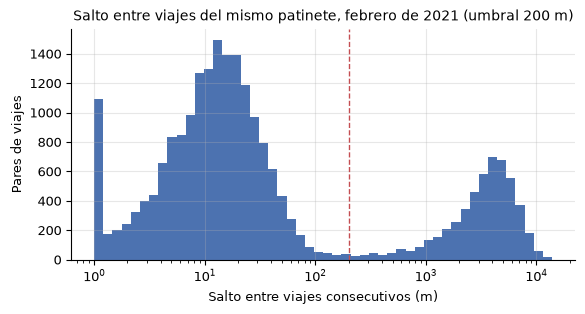

Solapes: 0


,salto_m
0.25,7.4
0.50,16.9
0.75,57.8
0.80,1167.9
0.90,3960.1
0.95,5440.3


In [2]:
solapes = int((pares["parado_h"] < 0).sum())
bordes = np.logspace(0, np.log10(pares["salto_m"].max() + 1), 51)
cuentas, _ = np.histogram(pares["salto_m"].clip(lower=1), bins=bordes)

fig, eje = plt.subplots(figsize=(6.5, 3.0))
eje.stairs(cuentas, bordes, fill=True, color="#4C72B0")
eje.axvline(UMBRAL, color="#C44E52", ls="--", lw=1)
eje.set_xscale("log")
eje.set_xlabel("Salto entre viajes consecutivos (m)")
eje.set_ylabel("Pares de viajes")
eje.set_title(f"Salto entre viajes del mismo patinete, febrero de 2021 (umbral {UMBRAL} m)")
guardar_figura(fig, TEMA, "T11_saltos")

cuantiles = pares["salto_m"].quantile([0.25, 0.5, 0.75, 0.8, 0.9, 0.95]).round(1)
print(f"Solapes: {solapes}")
display(cuantiles.rename("salto_m").to_frame())

**Conclusiones.**

- No hay solapes: ningún patinete empieza un viaje antes de terminar el anterior.
- La distribución tiene dos grupos claros. El primero es ruido de GPS (mediana 16,9 m, P75 57,8 m; la primera barra agrupa los saltos de menos de 1 m). El segundo son saltos de varios kilómetros, con el pico entre 3 y 6 km.
- Entre los dos hay un valle casi vacío de unos 100 a 500 m. Se toma **200 m** como umbral de recolocación, dentro del valle.

## 2. Sensibilidad al umbral de recolocación

**Qué queremos ver.** Cuántas recolocaciones se cuentan con umbrales de 100 m a 2 km.

**Por qué importa.** Si la cifra dependiera mucho del umbral, no podríamos usarla para dimensionar el rebalanceo. Si es estable, el umbral no es una decisión crítica.

In [3]:
sens = []
for u in CFG["umbrales_recolocacion_m"]:
    m = pares["salto_m"] > u
    sens.append({
        "umbral_m": u, "saltos": int(m.sum()),
        "porcentaje_encadenamientos": round(100 * m.mean(), 2),
        "patinetes_con_salto": int(pares.loc[m, "idS"].nunique()),
        "parado_h_mediana_con_salto": round(pares.loc[m, "parado_h"].median(), 1),
        "parado_h_mediana_sin_salto": round(pares.loc[~m, "parado_h"].median(), 1),
    })
sens = pd.DataFrame(sens)
sens.to_csv(TABLAS / "T11_saltos_sensibilidad.csv", index=False)

exportar(FASE, "t11_saltos", {
    "bordes_m": bordes.round(2), "cuentas": cuentas, "umbral_m": UMBRAL, "solapes": solapes,
    "pares": len(pares), "cuantiles_m": cuantiles.to_dict(), "sensibilidad": sens,
})
display(sens)

,umbral_m,saltos,porcentaje_encadenamientos,patinetes_con_salto,parado_h_mediana_con_salto,parado_h_mediana_sin_salto
0,100,5269,23.05,2101,96.9,5.8
1,200,5111,22.36,2094,98.8,5.8
2,300,5051,22.10,2091,99.4,5.8
3,500,4948,21.65,2084,99.7,6.0
4,1000,4683,20.49,2068,100.7,6.4
5,2000,3990,17.46,1980,102.3,7.7


**Conclusiones.**

- Con 200 m hay **5 111 recolocaciones** (22,4 % de los pares consecutivos) que afectan a 2 094 de los 2 331 patinetes.
- La cifra es estable: de 5 269 con 100 m a 4 683 con 1 km (−11 %). Solo con 2 km empieza a caer más, porque se mete en el grupo de los saltos grandes.

## 3. Cuándo: tiempo parado antes y después de recolocar

**Qué queremos ver.** Cuánto tiempo pasa entre el final de un viaje y el siguiente cuando hay recolocación y cuando no, si las recolocaciones ocurren dentro del mismo día de servicio y si incluyen la noche.

**Por qué importa.** Distingue dos operaciones distintas. Un rebalanceo durante el día mueve patinetes de donde sobran a donde faltan en pocas horas. Una recogida para recargar o reparar retira el patinete uno o varios días. Con estaciones de recarga la segunda desaparece y solo queda la primera.

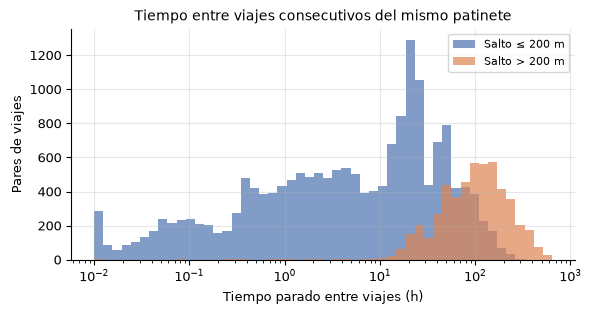

,valor
parado_h_mediana_con_salto,98.80
parado_h_mediana_sin_salto,5.80
recolocaciones_intradia_pc,0.94
recolocaciones_con_noche_pc,98.83


In [4]:
r = pares[pares["recolocacion"]].copy()
r["intradia"] = r["parado_h"] <= HORAS_INTRADIA
r["incluye_noche"] = incluye_noche(r["fin_anterior"], r["inicio"])
sin = pares[~pares["recolocacion"]]

bordes_h = np.logspace(-2, np.log10(pares["parado_h"].max() + 1), 51)
c_sin, _ = np.histogram(sin["parado_h"].clip(lower=0.01), bins=bordes_h)
c_con, _ = np.histogram(r["parado_h"].clip(lower=0.01), bins=bordes_h)

fig, eje = plt.subplots(figsize=(6.5, 3.0))
eje.stairs(c_sin, bordes_h, fill=True, alpha=0.7, color="#4C72B0", label=f"Salto ≤ {UMBRAL} m")
eje.stairs(c_con, bordes_h, fill=True, alpha=0.7, color="#DD8452", label=f"Salto > {UMBRAL} m")
eje.set_xscale("log")
eje.set_xlabel("Tiempo parado entre viajes (h)")
eje.set_ylabel("Pares de viajes")
eje.legend()
eje.set_title("Tiempo entre viajes consecutivos del mismo patinete")
guardar_figura(fig, TEMA, "T11_parado")

cuando = {
    "parado_h_mediana_con_salto": round(r["parado_h"].median(), 1),
    "parado_h_mediana_sin_salto": round(sin["parado_h"].median(), 1),
    "recolocaciones_intradia_pc": round(100 * r["intradia"].mean(), 2),
    "recolocaciones_con_noche_pc": round(100 * r["incluye_noche"].mean(), 2),
}
exportar(FASE, "t11_parado", {"bordes_h": bordes_h.round(4), "sin_salto": c_sin, "con_salto": c_con,
                              "umbral_m": UMBRAL, "horas_intradia": HORAS_INTRADIA, **cuando})
display(pd.Series(cuando).to_frame("valor"))

**Conclusiones.**

- Un patinete recolocado ha estado parado una mediana de **98,8 h**, frente a 5,8 h cuando no hay salto.
- Solo el 0,9 % de las recolocaciones ocurre en menos de 6 h y el 98,8 % incluye al menos una noche.
- No es rebalanceo dentro del día: encaja con recogidas para recargar o mantener que devuelven el patinete días después. En el escenario de rebalanceo de la fase 1 el operador trabajará de noche.

## 4. Dónde recoge y dónde entrega el operador

**Qué queremos ver.** Los puntos donde se recogen los patinetes (final del viaje anterior) y donde reaparecen (inicio del siguiente), y el saldo neto de entregas por celda H3.

**Por qué importa.** Si el operador devuelve los patinetes a pocos puntos, esos puntos son los que él considera buenos para empezar viajes: candidatos naturales a estación o a más stock inicial. El saldo por celda se contrastará con el saldo de orígenes y destinos de T14.

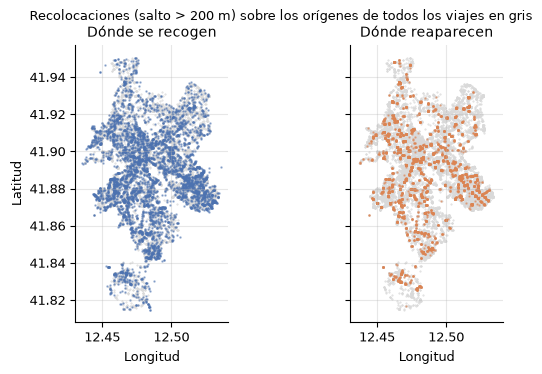

,valor
celdas_res10_recogida,1972
celdas_res10_entrega,628


,recogidas,entregas,neto_entregas
h3_res8,,,
881e805089fffff,161,251,90
881e8052a5fffff,110,176,66
881e8050c3fffff,169,221,52
881e805213fffff,35,86,51
881e8051dbfffff,77,127,50


,recogidas,entregas,neto_entregas
h3_res8,,,
881e8050e1fffff,62,24,-38
881e8051d3fffff,42,2,-40
881e80508bfffff,72,27,-45
881e80501dfffff,118,68,-50
881e8052adfffff,120,50,-70


In [5]:
celda = lambda lat, lon, res: [h3.latlng_to_cell(a, b, res) for a, b in zip(lat, lon)]
recogida = pd.Series(celda(r["lat_recogida"], r["lon_recogida"], RES)).value_counts()
entrega = pd.Series(celda(r["lat_entrega"], r["lon_entrega"], RES)).value_counts()
celdas = pd.DataFrame({"recogidas": recogida, "entregas": entrega}).fillna(0).astype("int64")
celdas["neto_entregas"] = celdas["entregas"] - celdas["recogidas"]
celdas.index.name = f"h3_res{RES}"
celdas = celdas.sort_values("neto_entregas", ascending=False)
celdas.reset_index().to_csv(TABLAS / f"T11_celdas_res{RES}.csv", index=False)
puntos = {
    f"celdas_res{RES_PUNTOS}_recogida": len(set(celda(r["lat_recogida"], r["lon_recogida"], RES_PUNTOS))),
    f"celdas_res{RES_PUNTOS}_entrega": len(set(celda(r["lat_entrega"], r["lon_entrega"], RES_PUNTOS))),
}

fig, ejes = plt.subplots(1, 2, figsize=(6.5, 3.6), sharex=True, sharey=True)
for eje, (lat, lon, titulo, color) in zip(ejes, [
    ("lat_recogida", "lon_recogida", "Dónde se recogen", "#4C72B0"),
    ("lat_entrega", "lon_entrega", "Dónde reaparecen", "#DD8452"),
]):
    eje.scatter(viajes["lonO"], viajes["latO"], s=0.2, color="0.85", rasterized=True)
    eje.scatter(r[lon], r[lat], s=0.6, color=color, alpha=0.5, rasterized=True)
    eje.set_title(titulo)
    eje.set_xlabel("Longitud")
    eje.set_aspect(1 / np.cos(np.radians(41.9)))
ejes[0].set_ylabel("Latitud")
fig.suptitle(f"Recolocaciones (salto > {UMBRAL} m) sobre los orígenes de todos los viajes en gris", fontsize=9)
guardar_figura(fig, TEMA, "T11_mapa_recolocaciones")

exportar(FASE, "t11_mapa", {
    "recogida": {"lat": r["lat_recogida"].round(5), "lon": r["lon_recogida"].round(5)},
    "entrega": {"lat": r["lat_entrega"].round(5), "lon": r["lon_entrega"].round(5)},
    "umbral_m": UMBRAL, **puntos,
})
display(pd.Series(puntos).to_frame("valor"), celdas.head(5), celdas.tail(5))

**Conclusiones.**

- Los patinetes se recogen por toda el área de servicio, pero reaparecen en muchos menos sitios: 628 celdas H3 de resolución 10 frente a 1 972 donde se recogen.
- El operador concentra las entregas en unos puntos de despliegue; la celda de resolución 8 que más recibe gana 90 patinetes netos en el mes.
- Esos puntos de despliegue son candidatos a estación o a más stock inicial, y su saldo se cruzará con el de T14.

## 5. Resumen por día y tabla de indicadores

**Qué queremos ver.** Cuántas recolocaciones hay cada día frente a los viajes y a los patinetes que se usan, y la tabla de indicadores que cita la memoria.

**Por qué importa.** Da el orden de magnitud del trabajo del operador hoy, que es la referencia con la que se comparará el rebalanceo de la red con estaciones.

In [6]:
n_dias = viajes["tsO"].dt.date.nunique()
dia_viajes = viajes.groupby(viajes["tsO"].dt.date).agg(viajes=("trip_id", "size"),
                                                       patinetes_activos=("idS", "nunique"))
dia_rec = r.groupby(r["inicio"].dt.date).size().rename("recolocaciones")
por_dia = dia_viajes.join(dia_rec).fillna({"recolocaciones": 0}).astype("int64")
por_dia.index.name = "fecha"
por_dia.reset_index().to_csv(TABLAS / "T11_por_dia.csv", index=False)

resumen = tabla_indicadores([
    ("viajes", len(viajes)),
    ("patinetes", viajes["idS"].nunique()),
    ("encadenamientos", len(pares)),
    ("solapes", solapes),
    ("salto_m_mediana", round(pares["salto_m"].median(), 1)),
    ("salto_m_p75", round(pares["salto_m"].quantile(0.75), 1)),
    ("umbral_recolocacion_m", UMBRAL),
    ("recolocaciones", len(r)),
    ("recolocaciones_pc_encadenamientos", round(100 * len(r) / len(pares), 2)),
    ("recolocaciones_por_dia_media", round(len(r) / n_dias, 1)),
    ("recolocacion_salto_km_mediana", round(r["salto_m"].median() / 1000, 2)),
    ("recolocacion_parado_h_mediana", cuando["parado_h_mediana_con_salto"]),
    ("sin_salto_parado_h_mediana", cuando["parado_h_mediana_sin_salto"]),
    ("recolocaciones_intradia_pc", cuando["recolocaciones_intradia_pc"]),
    ("recolocaciones_con_noche_pc", cuando["recolocaciones_con_noche_pc"]),
    ("patinetes_recolocados", r["idS"].nunique()),
    *puntos.items(),
])
resumen.to_csv(TABLAS / "T11_resumen.csv", index=False)
exportar(FASE, "t11_resumen", {"indicadores": dict(zip(resumen["indicador"], resumen["valor"])),
                               "por_dia": por_dia.reset_index()})
display(resumen, por_dia.describe().round(1))

,indicador,valor
0,viajes,25186
1,patinetes,2331
2,encadenamientos,22855
3,solapes,0
4,salto_m_mediana,16.9
5,salto_m_p75,57.8
6,umbral_recolocacion_m,200
7,recolocaciones,5111
8,recolocaciones_pc_encadenamientos,22.36
9,recolocaciones_por_dia_media,182.5


,viajes,patinetes_activos,recolocaciones
count,28.0,28.0,28.0
mean,899.5,539.8,182.5
std,163.9,87.4,82.6
min,430.0,283.0,3.0
25%,796.8,477.2,139.5
50%,897.5,551.5,195.5
75%,1008.8,596.0,245.8
max,1172.0,692.0,310.0


**Conclusiones.**

- El operador recoloca de media **182,5 patinetes al día**, con un salto mediano de 3,67 km.
- Cada día se usan de media 540 patinetes distintos (entre 283 y 692), así que el operador mueve cada día el equivalente a un tercio de la flota activa.
- Con estaciones de recarga desaparecen las recogidas para cargar. La pregunta para la simulación es cuánto rebalanceo nocturno queda por la acumulación de patinetes que mida T14.

## 6. Viajes encadenados

**Qué queremos ver.** Los pares de viajes elegibles consecutivos del mismo patinete en los que el segundo sale a menos de 50 m de donde acabó el primero y con poca pausa. Se mira cuántos hay según la pausa, cómo se reparten las pausas y hacia dónde va el segundo viaje: si sigue en la misma dirección que el primero (un trayecto partido en dos) o vuelve hacia atrás (ida y vuelta, otro usuario).

**Por qué importa.** Es el caso contrario a los viaje con paradas de T10: un desplazamiento real puede quedar registrado como dos viajes si el usuario cierra y abre el alquiler en el mismo sitio. Si fueran muchos, la matriz OD tendría destinos y orígenes intermedios que no son el fin del trayecto. La sensibilidad de la red a unirlos se mide en T30.

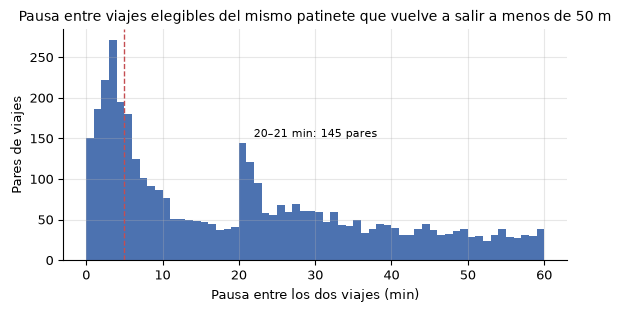

,grupo,pausa_max_s,pares,pct_viajes_elegibles,pct_sigue,pct_vuelve,pct_ida_y_vuelta,dis_m_mediana_primero,dis_m_mediana_segundo
0,pausa <= 60 s,60,163,0.70,28.8,44.2,22.7,1498.0,1252.0
1,pausa <= 120 s,120,352,1.51,32.1,41.8,20.2,1117.0,1128.0
2,pausa <= 300 s,300,1045,4.47,28.7,47.3,20.5,1074.0,1106.0
3,pausa <= 600 s,600,1615,6.91,26.8,49.8,22.4,1082.0,1103.0
4,pausa <= 1800 s,1800,2893,12.38,24.9,52.6,21.6,1334.0,1269.0
5,referencia 1-6 h,21600,3611,15.45,20.3,55.5,17.5,1664.0,1658.0


,valor
pares_principal,1045.00
viajes_elegibles,23370.00
viajes_unidos,22325.00
pct_viajes_menos,4.47
cadenas_de_3_o_mas,124.00
pico_pausa_min,20.00
pico_pares,145.00
pico_vecinos_media,55.50


In [7]:
from comun.encadenados import encadenado, fusionar, pares_consecutivos

ENCADENADO = {
    # El segundo viaje sale a menos de salto_max_m del final del primero.
    "salto_max_m": 50,
    # Pausas máximas que se prueban; la principal es pausa_s.
    "pausas_s": [60, 120, 300, 600, 1800],
    "pausa_s": 300,
    # Ángulo entre los rumbos origen→destino de los dos viajes: sigue si es menor que
    # continua_max_grados y vuelve si es mayor que vuelve_min_grados.
    "continua_max_grados": 60,
    "vuelve_min_grados": 120,
    # Ida y vuelta: el segundo viaje acaba a menos de esto del origen del primero.
    "vuelta_origen_m": 200,
    # Referencia: pares en el mismo sitio con una pausa de 1 a 6 h (dos viajes distintos).
    "referencia_h": [1, 6],
}


def rumbo(lat1, lon1, lat2, lon2):
    """Rumbo inicial en grados del punto 1 al punto 2."""
    f1, f2, dl = np.radians(lat1), np.radians(lat2), np.radians(lon2 - lon1)
    return np.degrees(np.arctan2(np.sin(dl) * np.cos(f2),
                                 np.cos(f1) * np.sin(f2) - np.sin(f1) * np.cos(f2) * np.cos(dl)))


e = ENCADENADO
elegibles = viajes[viajes["elegible"]]
enc = pares_consecutivos(elegibles)
giro = rumbo(enc["latO_b"], enc["lonO_b"], enc["latD_b"], enc["lonD_b"]) - rumbo(
    enc["latO_a"], enc["lonO_a"], enc["latD_a"], enc["lonD_a"])
enc["angulo"] = np.abs((giro + 180) % 360 - 180)
enc["vuelta_m"] = haversine_m(enc["latD_b"], enc["lonD_b"], enc["latO_a"], enc["lonO_a"])
mismo_sitio = enc["salto_m"] <= e["salto_max_m"]


def direccion(sub):
    return {"pct_sigue": round(100 * (sub["angulo"] < e["continua_max_grados"]).mean(), 1),
            "pct_vuelve": round(100 * (sub["angulo"] > e["vuelve_min_grados"]).mean(), 1),
            "pct_ida_y_vuelta": round(100 * (sub["vuelta_m"] <= e["vuelta_origen_m"]).mean(), 1),
            "dis_m_mediana_primero": round(sub["dis_m_a"].median(), 0),
            "dis_m_mediana_segundo": round(sub["dis_m_b"].median(), 0)}


filas = []
for p in e["pausas_s"]:
    sub = enc[encadenado(enc, e["salto_max_m"], p)]
    filas.append({"grupo": f"pausa <= {p} s", "pausa_max_s": p, "pares": len(sub),
                  "pct_viajes_elegibles": round(100 * len(sub) / len(elegibles), 2), **direccion(sub)})
h0, h1 = e["referencia_h"]
ref = enc[mismo_sitio & enc["pausa_s"].between(h0 * 3600, h1 * 3600)]
filas.append({"grupo": f"referencia {h0}-{h1} h", "pausa_max_s": h1 * 3600, "pares": len(ref),
              "pct_viajes_elegibles": round(100 * len(ref) / len(elegibles), 2), **direccion(ref)})
encadenados = pd.DataFrame(filas)
encadenados.to_csv(TABLAS / "T11_encadenados.csv", index=False)

# Pausas de 0 a 60 min, por minuto, en los pares en el mismo sitio.
bordes_min = np.arange(0, 61, 1)
cuentas_min, _ = np.histogram(enc.loc[mismo_sitio, "pausa_s"] / 60, bins=bordes_min)
pico = int(np.argmax(cuentas_min[10:])) + 10
alrededor = np.r_[cuentas_min[pico - 5:pico - 1], cuentas_min[pico + 2:pico + 6]]

fig, eje = plt.subplots(figsize=(6.5, 3.0))
eje.stairs(cuentas_min, bordes_min, fill=True, color="#4C72B0")
eje.axvline(e["pausa_s"] / 60, color="#C44E52", ls="--", lw=1)
eje.annotate(f"{pico}–{pico + 1} min: {cuentas_min[pico]} pares", (pico + 0.5, cuentas_min[pico]),
             xytext=(8, 4), textcoords="offset points", fontsize=8)
eje.set_xlabel("Pausa entre los dos viajes (min)")
eje.set_ylabel("Pares de viajes")
eje.set_title(f"Pausa entre viajes elegibles del mismo patinete que vuelve a salir a menos de {e['salto_max_m']} m")
guardar_figura(fig, TEMA, "T11_encadenados")

# Si se unieran: viajes y extremos que cambian.
unidos = fusionar(elegibles, e["salto_max_m"], e["pausa_s"])
principal = encadenados.set_index("pausa_max_s").loc[e["pausa_s"]]
union = {
    "pares_principal": int(principal["pares"]),
    "viajes_elegibles": len(elegibles),
    "viajes_unidos": len(unidos),
    "pct_viajes_menos": round(100 * (1 - len(unidos) / len(elegibles)), 2),
    "cadenas_de_3_o_mas": int((unidos["tramos"] >= 3).sum()),
    "pico_pausa_min": pico,
    "pico_pares": int(cuentas_min[pico]),
    "pico_vecinos_media": round(float(alrededor.mean()), 1),
}
exportar(FASE, "t11_encadenados", {"parametros": e, "tabla": encadenados, "bordes_min": bordes_min,
                                   "cuentas_min": cuentas_min, **union})
display(encadenados, pd.Series(union).to_frame("valor"))

**Conclusiones.**

- Con una pausa de 5 min como mucho y un salto de 50 m como mucho hay **1 045 pares** de viajes elegibles encadenados, el 4,47 % de los 23 370 elegibles. Con 1 min son 163 y con 30 min, 2 893.
- Casi ninguno parece un trayecto partido en dos. El segundo viaje sigue la dirección del primero en el 28,7 % de los pares y vuelve hacia atrás en el 47,3 %. En la referencia (pares separados de 1 a 6 h, claramente viajes distintos) los porcentajes son 20,3 % y 55,5 %. Solo el exceso de unos 8 puntos en «sigue», unos 90 pares, podría ser de trayectos partidos. Uno de cada cinco pares es una ida y vuelta.
- Las pausas tienen un salto brusco a los 20 min: 145 pares tienen una pausa de 20 a 21 min, frente a 37–47 por minuto entre los 15 y los 20 min. Parece una regla de la aplicación que los datos no explican. No afecta a la decisión, que usa 5 min.
- Unirlos quitaría el 4,47 % de los viajes (quedarían 22 325) y 124 cadenas tendrían tres viajes o más. **Se mantienen como viajes separados.** Cada uno es un alquiler pagado y el patinete se queda aparcado en el punto intermedio. T30 comprueba que la cobertura de la red apenas cambia si se unen.

## 7. Concentración de los puntos de entrega

**Qué queremos ver.** Qué parte de las entregas del operador cae en sus celdas más usadas (H3 de resolución 9, la de los candidatos a estación), comparada con las recogidas y con los orígenes de los viajes elegibles.

**Por qué importa.** El apartado 4 dice que las entregas se concentran en menos sitios que las recogidas. Medirlo con cuotas evita que la conclusión dependa del número de celdas, que crece con los puntos. Si el operador ya tiene puntos de despliegue, la red debe cubrirlos; se comprueba en T30.

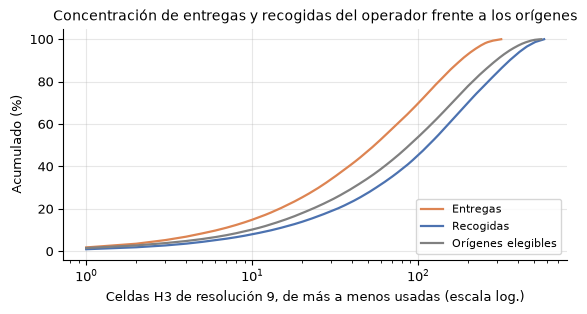

,serie,puntos,celdas,pct_top10_celdas,pct_top20_celdas,pct_top50_celdas,pct_top100_celdas
0,entregas,5111,317,14.9,25.4,47.4,69.8
1,recogidas,5111,575,8.0,13.9,27.6,45.3
2,origenes_elegibles,23370,552,10.2,18.0,34.5,53.9


In [8]:
RES_CAND = cargar_config()["movilidad"]["resolucion_candidatos"]
cuenta = lambda lat, lon: pd.Series(celda(lat, lon, RES_CAND)).value_counts()
series = {"entregas": cuenta(r["lat_entrega"], r["lon_entrega"]),
          "recogidas": cuenta(r["lat_recogida"], r["lon_recogida"]),
          "origenes_elegibles": cuenta(elegibles["latO"], elegibles["lonO"])}
filas = []
for nombre, s in series.items():
    fila = {"serie": nombre, "puntos": int(s.sum()), "celdas": len(s)}
    for k in (10, 20, 50, 100):
        fila[f"pct_top{k}_celdas"] = round(100 * s.head(k).sum() / s.sum(), 1)
    filas.append(fila)
concentracion = pd.DataFrame(filas)
concentracion.to_csv(TABLAS / f"T11_concentracion_res{RES_CAND}.csv", index=False)

fig, eje = plt.subplots(figsize=(6.5, 3.0))
for (nombre, s), color in zip(series.items(), ["#DD8452", "#4C72B0", "0.5"]):
    eje.plot(np.arange(1, len(s) + 1), 100 * s.cumsum() / s.sum(), color=color, lw=1.6,
             label={"entregas": "Entregas", "recogidas": "Recogidas", "origenes_elegibles": "Orígenes elegibles"}[nombre])
eje.set_xscale("log")
eje.set_xlabel(f"Celdas H3 de resolución {RES_CAND}, de más a menos usadas (escala log.)")
eje.set_ylabel("Acumulado (%)")
eje.legend(loc="lower right")
eje.set_title("Concentración de entregas y recogidas del operador frente a los orígenes")
guardar_figura(fig, TEMA, "T11_concentracion")

exportar(FASE, "t11_concentracion", {"res": RES_CAND, "tabla": concentracion,
                                     "curvas": {n: np.round(100 * s.cumsum().to_numpy() / s.sum(), 2)
                                                for n, s in series.items()}})
display(concentracion)

**Conclusiones.**

- Las entregas del operador están más concentradas que las recogidas y que los orígenes. Sus 20 celdas de resolución 9 más usadas reciben el 25,4 % de las entregas. Las 20 principales de las recogidas reúnen el 13,9 % y las de los orígenes elegibles, el 18,0 %. Las entregas caen en 317 celdas y las recogidas en 575.
- Confirma, con una medida que no depende del número de celdas, que el operador trabaja con puntos de despliegue. Según T30, el 90,3 % de las entregas queda a menos de 300 m de la red principal.